# Opening the RQs of a `goldsluice` run, written as ROOT files, with `goldpan`

*A third example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-27.*

`goldsluice` can write what it computes as one ROOT file per dump, in the layout of the collaboration's RQ files: event numbers in `rqDir/eventTree`, the quantities of detector number 1 in `rqDir/zip1`, and a record of what was run in `infoDir/goldsluice`. `goldpan.adapters.rq_root.read` opens such files like any other RQ file, so everything in `rq-histogram-goldpan.ipynb` works on them.

**The data.** The run of `goldsluice/examples/r76.dataset.toml` on the real Run 76 series `07221203_2025` (Side-2 readout, 30 dumps, 81,992 events), written to `~/goldsluice-output/r76-07221203/` (set `OUTPUT` below to move it). It is not in the repository. Two algorithms ran, `peak` and `max_time`, so each of the six phonon channels has three quantities: `adc_max` (the largest ADC value), `current_max` (the largest value above the pretrigger baseline) and `max_time_s` (the time of that maximum from the start of the trace, in seconds). `current_max` is in **ADC counts**: `amps_per_adc` is a placeholder equal to 1 until the ADC-to-amps scale is known.

Needs `uproot` and `goldpan` (both in `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
import os
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import uproot

from goldpan.adapters import rq_root

In [2]:
OUTPUT = Path(os.path.expanduser("~/goldsluice-output/r76-07221203"))     # the folder `goldsluice run` wrote
files = sorted(OUTPUT.glob("*.root"))
assert files, f"no .root files in {OUTPUT}: run `python -m goldsluice run` with the ROOT writer first"
print(len(files), "files, from", files[0].name, "to", files[-1].name, f"({sum(f.stat().st_size for f in files) / 1e6:.1f} MB)")

30 files, from 07221203_2025_F0001.root to 07221203_2025_F0030.root (5.4 MB)


## The structure of a file

Every file has the same layout. Printed from the first dump:

In [3]:
# The structure of one file: its directories, its trees, and the branches of each tree.
with uproot.open(files[0]) as f:
    for key, cls in f.classnames().items():
        obj = f[key]
        if hasattr(obj, "num_entries"):
            types = obj.typenames()
            print(f"{key.split(';')[0]:<22} {cls}, {obj.num_entries} entries, {len(types)} branches")
            for name, t in types.items():
                print(f"    {name:<24} {t}")
        else:
            print(f"{key.split(';')[0]:<22} {cls}")
    info = json.loads(str(f["infoDir/goldsluice"]))
print()
print("infoDir/goldsluice says: algorithms", [s["algorithm"] for s in info["steps"]], "of the raw dump", Path(info["raw"]).name,
      "; written by goldsluice", info["version"], "(", info["backend"], "backend )")

rqDir                  TDirectory
rqDir/eventTree        ROOT::RNTuple, 1517 entries, 3 branches
    DumpNumber               double
    EventNumber              double
    SeriesNumber             double
rqDir/zip1             ROOT::RNTuple, 1517 entries, 18 branches
    Side2pA_adc_max          double
    Side2pA_current_max      double
    Side2pA_max_time_s       double
    Side2pB_adc_max          double
    Side2pB_current_max      double
    Side2pB_max_time_s       double
    Side2pC_adc_max          double
    Side2pC_current_max      double
    Side2pC_max_time_s       double
    Side2pD_adc_max          double
    Side2pD_current_max      double
    Side2pD_max_time_s       double
    Side2pE_adc_max          double
    Side2pE_current_max      double
    Side2pE_max_time_s       double
    Side2pF_adc_max          double
    Side2pF_current_max      double
    Side2pF_max_time_s       double
infoDir                TDirectory
infoDir/goldsluice     TObjString

infoDir/goldsl

The same, as a picture (saved next to this notebook as `goldsluice-root-structure.png`):

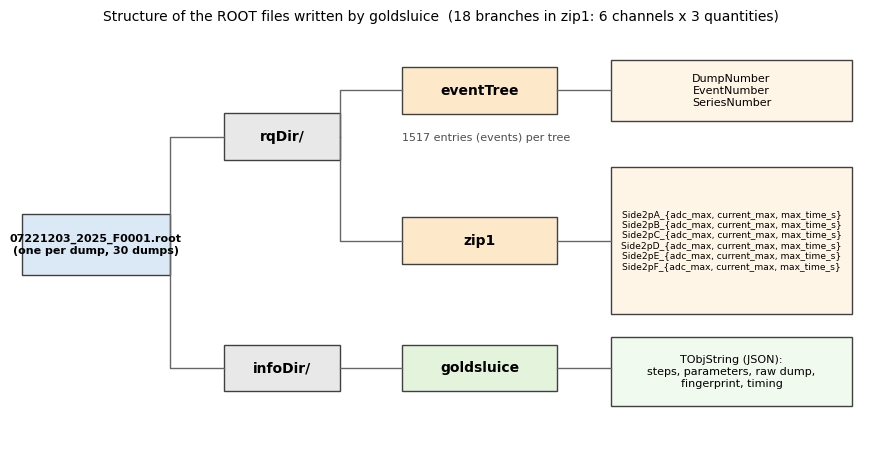

In [4]:
# The structure as a diagram: file > directories > trees > branches (the six channels' branches grouped).
with uproot.open(files[0]) as f:
    event_branches = list(f["rqDir/eventTree"].keys())
    zip_branches = list(f["rqDir/zip1"].keys())
    n_entries = f["rqDir/zip1"].num_entries
channels = sorted({b.split("_")[0] for b in zip_branches})
quantities = [b[len(channels[0]) + 1:] for b in zip_branches if b.startswith(channels[0] + "_")]

def box(ax, x, y, w, h, text, color, fs=9, weight="normal"):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=color, ec="0.25", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight=weight)

def line(ax, x0, y0, x1, y1):
    ax.plot([x0, x0, x1], [y0, y1, y1], color="0.4", lw=1)

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.set_xlim(0, 11)
ax.set_ylim(0, 5.6)
ax.axis("off")
box(ax, 0.1, 2.4, 1.9, 0.8, f"{files[0].name}\n(one per dump, {len(files)} dumps)", "#dbe9f6", 8, "bold")
box(ax, 2.7, 3.9, 1.5, 0.6, "rqDir/", "#e8e8e8", 10, "bold")
box(ax, 2.7, 0.9, 1.5, 0.6, "infoDir/", "#e8e8e8", 10, "bold")
line(ax, 2.0, 2.8, 2.7, 4.2)
line(ax, 2.0, 2.8, 2.7, 1.2)
box(ax, 5.0, 4.5, 2.0, 0.6, "eventTree", "#fde9c9", 10, "bold")
box(ax, 5.0, 2.55, 2.0, 0.6, "zip1", "#fde9c9", 10, "bold")
line(ax, 4.2, 4.2, 5.0, 4.8)
line(ax, 4.2, 4.2, 5.0, 2.85)
box(ax, 5.0, 0.9, 2.0, 0.6, "goldsluice", "#e3f3dc", 10, "bold")
line(ax, 4.2, 1.2, 5.0, 1.2)
ax.text(5.0, 4.15, f"{n_entries} entries (events) per tree", fontsize=8, color="0.3")
box(ax, 7.7, 4.4, 3.1, 0.8, "\n".join(event_branches), "#fff5e6", 8)
line(ax, 7.0, 4.8, 7.7, 4.8)
rows = [f"{c}_" + "{" + ", ".join(quantities) + "}" for c in channels]
box(ax, 7.7, 1.9, 3.1, 1.9, "\n".join(rows), "#fff5e6", 6.6)
line(ax, 7.0, 2.85, 7.7, 2.85)
box(ax, 7.7, 0.7, 3.1, 0.9, "TObjString (JSON):\nsteps, parameters, raw dump,\nfingerprint, timing", "#f1faee", 8)
line(ax, 7.0, 1.2, 7.7, 1.2)
ax.set_title(f"Structure of the ROOT files written by goldsluice  ({len(zip_branches)} branches in zip1: "
             f"{len(channels)} channels x {len(quantities)} quantities)", fontsize=10)
fig.savefig("goldsluice-root-structure.png", dpi=130, bbox_inches="tight")
plt.show()

## Reading the RQs with `goldpan`

`rq_root.read` takes the folder; the detector number (`zip1` is detector 1) is never assumed, so it is given. The first fields are the event key (`series`, `dump`, `event`), then the branches of `eventTree`, then those of `zip1`.

In [5]:
table = rq_root.read(OUTPUT, detector=1)       # a folder of .root files is read file after file

print(len(table), "events;", len(ak.fields(table)), "fields")
print(ak.fields(table))
print()
print("the first event:")
for k, v in ak.to_list(table[0]).items():
    print(f"  {k:<20} {v}")

81992 events; 24 fields
['series', 'dump', 'event', 'DumpNumber', 'EventNumber', 'SeriesNumber', 'Side2pA_adc_max', 'Side2pA_current_max', 'Side2pA_max_time_s', 'Side2pB_adc_max', 'Side2pB_current_max', 'Side2pB_max_time_s', 'Side2pC_adc_max', 'Side2pC_current_max', 'Side2pC_max_time_s', 'Side2pD_adc_max', 'Side2pD_current_max', 'Side2pD_max_time_s', 'Side2pE_adc_max', 'Side2pE_current_max', 'Side2pE_max_time_s', 'Side2pF_adc_max', 'Side2pF_current_max', 'Side2pF_max_time_s']

the first event:
  series               07221203_2025
  dump                 F0001
  event                10000
  DumpNumber           1.0
  EventNumber          10000.0
  SeriesNumber         72212032025.0
  Side2pA_adc_max      3294.0
  Side2pA_current_max  5.72424242424222
  Side2pA_max_time_s   0.00010159999999999999
  Side2pB_adc_max      3322.0
  Side2pB_current_max  7.961616161616348
  Side2pB_max_time_s   7.04e-05
  Side2pC_adc_max      3141.0
  Side2pC_current_max  4.265656565656627
  Side2pC_max_time_s 

In [6]:
# The quantities of every channel, as plain arrays.
channels = sorted({f.split("_")[0] for f in ak.fields(table) if f.startswith("Side2p")})
rq = lambda ch, name: ak.to_numpy(table[f"{ch}_{name}"]).astype(float)
dump = ak.to_numpy(table["dump"])

print(f"{'':9}{'adc_max':>10}{'current_max (median)':>24}{'max_time_s (median)':>24}")
for ch in channels:
    print(f"{ch:<9}{np.nanmedian(rq(ch, 'adc_max')):>10.0f}{np.nanmedian(rq(ch, 'current_max')):>24.1f}{np.nanmedian(rq(ch, 'max_time_s')) * 1e6:>21.0f} us")

            adc_max    current_max (median)     max_time_s (median)
Side2pA        4143                   449.5                  476 us
Side2pB        3935                   329.8                  493 us
Side2pC        3423                   110.8                  502 us
Side2pD        3753                   250.9                  480 us
Side2pE        3526                   143.4                  498 us
Side2pF        3703                   209.3                  494 us


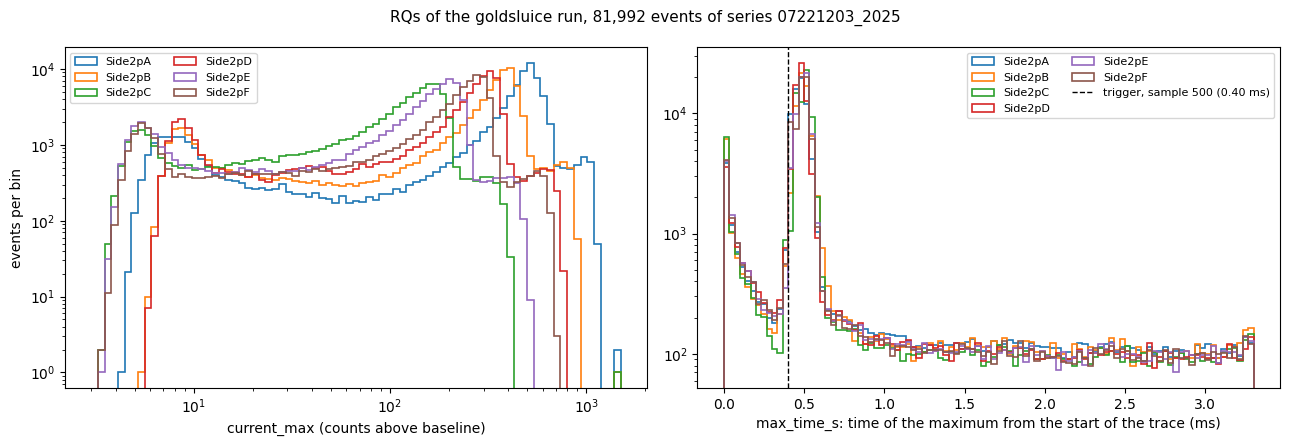

In [7]:
# The quantities, histogrammed: current_max (counts above baseline, log) and the time of the maximum in the trace.
trigger_s = 500 * 0.8e-6        # the trigger of this series is at sample 500 of the trace (0.8 us per sample)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(np.log10(3), np.log10(1500), 80)
for ch in channels:
    ax1.hist(np.clip(rq(ch, "current_max"), bins[0], bins[-1]), bins=bins, histtype="step", lw=1.2, label=ch)
    ax2.hist(rq(ch, "max_time_s") * 1e3, bins=np.linspace(0, 3.3, 100), histtype="step", lw=1.2, label=ch)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("current_max (counts above baseline)")
ax1.set_ylabel("events per bin")
ax2.set_yscale("log")
ax2.axvline(trigger_s * 1e3, color="k", ls="--", lw=1, label=f"trigger, sample 500 ({trigger_s * 1e3:.2f} ms)")
ax2.set_xlabel("max_time_s: time of the maximum from the start of the trace (ms)")
ax1.legend(fontsize=8, ncol=2)
ax2.legend(fontsize=8, ncol=2)
fig.suptitle(f"RQs of the goldsluice run, {len(table):,} events of series 07221203_2025", fontsize=11)
fig.tight_layout()
plt.show()

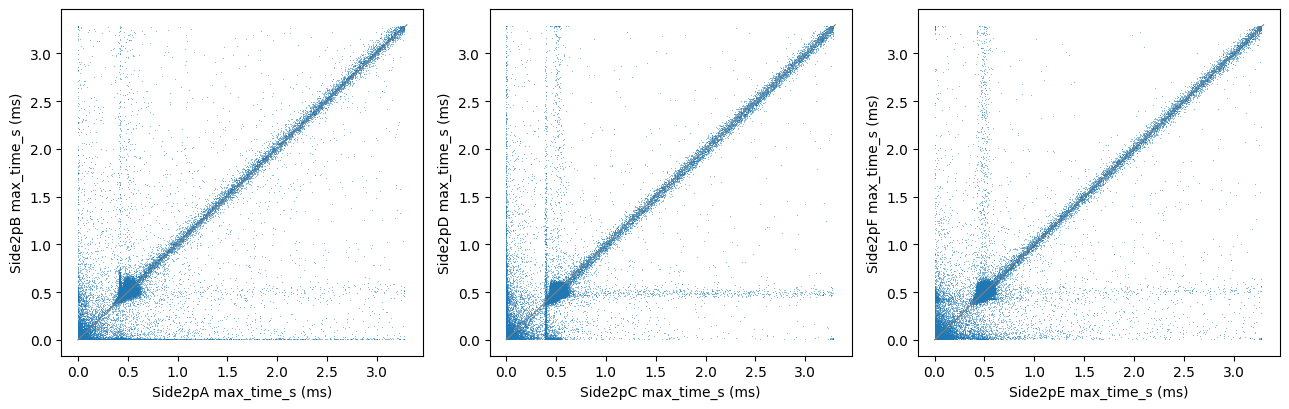

In [8]:
# Do the channels see the pulse at the same time? The time of the maximum of one channel against another.
pairs = [("Side2pA", "Side2pB"), ("Side2pC", "Side2pD"), ("Side2pE", "Side2pF")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (a, b) in zip(axes, pairs):
    ax.plot(rq(a, "max_time_s") * 1e3, rq(b, "max_time_s") * 1e3, ",", color="C0", alpha=0.5)
    ax.plot([0, 3.3], [0, 3.3], color="0.5", lw=0.8)
    ax.set_xlabel(f"{a} max_time_s (ms)")
    ax.set_ylabel(f"{b} max_time_s (ms)")
fig.tight_layout()
plt.show()

**What this shows, and what is next.** The ROOT files `goldsluice` writes are ordinary RQ files for `goldpan`: `rq_root.read` gives one record per event with every quantity as a field, named `<channel>_<quantity>`. Each new algorithm in `goldsluice` adds one branch per channel to `zip1`, so this notebook needs no change to see it. The same run also exists as a `goldpan` Parquet dataset (see `goldsluice-processed-plots.ipynb`), which keeps one record per channel instead of flat branch names.

To draw the traces under these quantities, read the raw dump and join on `series`, `dump` and `event` with `goldpan.adapters.rq.attach`, as at the end of `rq-histogram-goldpan.ipynb`.